In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.metrics import roc_auc_score, precision_score, confusion_matrix, ConfusionMatrixDisplay # Precision score is important when working with Imbalanced data.
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, TransformerMixin

# TransformerMixin gives your class a `.fit_transform()` method for free, you only had to write `fit()` and `transform()` yourself.

In [3]:
train = pd.read_csv("C:\\Users\\sulem\\OneDrive\\Desktop\\Codes\\ML\\Datasets\\Credit Card Fraud Detection\\train.csv")

trainx = train.drop("is_fraud", axis = 1)
trainy = train["is_fraud"]

test = pd.read_csv("C:\\Users\\sulem\\OneDrive\\Desktop\\Codes\\ML\\Datasets\\Credit Card Fraud Detection\\test.csv")

testx = test.drop("is_fraud", axis = 1)
testy = test["is_fraud"]

In [4]:
def FeatureTransformation(df):

    df = df.copy()

    dt = pd.to_datetime(df['trans_date_trans_time'])
    df['hour'] = dt.dt.hour
    df['day_of_week'] = dt.dt.dayofweek

    # Earth coordinates must be in radians for trigonometric functions
    customer_latitude_rad = np.radians(df['lat'])
    customer_longitude_rad = np.radians(df['long'])

    merch_latitude_rad = np.radians(df['merch_lat'])
    merch_longitude_rad = np.radians(df['merch_long'])

    # Project the flat coordinates onto a 3D sphere

    # x, y, z for customer location:
    df['cust_x'] = np.cos(customer_latitude_rad) * np.cos(customer_longitude_rad)
    df['cust_y'] = np.cos(customer_latitude_rad) * np.sin(customer_longitude_rad)
    df['cust_z'] = np.sin(customer_latitude_rad)

    # x, y, z for merchant location:
    df['merch_x'] = np.cos(merch_latitude_rad) * np.cos(merch_longitude_rad)
    df['merch_y'] = np.cos(merch_latitude_rad) * np.sin(merch_longitude_rad)
    df['merch_z'] = np.sin(merch_latitude_rad)

    df = df.sort_values(['cc_num', 'trans_date_trans_time'])
    dt_sorted = pd.to_datetime(df['trans_date_trans_time']) # Recompute dt after the sort so it's correct regardless of input order.
    df['time_since_last_trans'] = dt_sorted.groupby(df['cc_num']).diff().dt.total_seconds().fillna(-1)

    df = df.sort_index()   # undo the sort, restore original row order to match y

    '''

       These are Velocity features and are used to capture how "fast" a card is being used.

       sort_values(['cc_num', 'trans_date_trans_time']):
       Groups every card's transactions together and puts them in batches in time order so we can compare recent transaction with an old one.

       Example for one card (cc_num = 111):

       row   time            amt   time_since_last_trans   card_txn_count
       0     09:00:00        $50   -1                        0
       1     09:02:00        $900  120                       1
       2     Jan 2, 15:00    $60   107880                    2

       row 0: card's FIRST transaction on record -> nothing came before it, so time_since_last_trans = -1 (placeholder), card_txn_count = 0.
       row 1: came 120 seconds after row 0, SAME card -> suspiciously fast jump to $900 = classic fraud pattern
       row 2: came ~30 hours (107880s) after row 1 -> a normal gap

       Each card's counter resets independently (a different card like cc_num = 222 starts back at -1 / 0 for its own first transaction).

    '''

    df['card_txn_count'] = df.groupby('cc_num').cumcount()

    '''
    
       cumcount(): a running counter of how many transactions we've SEEN SO FAR for each card, starting at 0.

       Example, one card (cc_num = 111) with 3 transactions in time order:

       row   cc_num   card_txn_count
       0     111      0   <- this card's 1st transaction on record (0 seen before it)
       1     111      1   <- this card's 2nd transaction (1 seen before it)
       2     111      2   <- this card's 3rd transaction (2 seen before it)
    
       A different card (cc_num = 222) starts its OWN count back at 0 --
       cumcount() resets independently per group, it never mixes counts across different cards.
    
       Why it matters for fraud: a low count (0, 1, 2...) means we have little to no history on this card yet ,new/unfamiliar cards 
       behave differently from cards with a long, established transaction history, so this gives the model a sense of 
       "how much do we actually know about this card so far."
    
    '''

    df = df.drop(["Unnamed: 0", "trans_date_trans_time", "first", "last", "street", "zip", "dob", "trans_num", "unix_time", "lat", 
                 "long", "merch_lat", "merch_long", "cc_num"], axis = 1)

    return df

In [5]:
combined = pd.concat([trainx, testx], keys=['train', 'test'])
combined_raw = combined.reset_index(drop=True)
transformed_combined = FeatureTransformation(combined)   # full continuous card history, no resets

trainx = transformed_combined.xs('train')
testx = transformed_combined.xs('test')

'''

xs('train') / .xs('test') are the "cross-section" selector for a MultiIndex.

pd.concat([trainx, testx], keys=['train', 'test']) stacks an outer label on top of each row's original index, turning plain row 
labels like 0, 1, 2 into pairs: ('train', 0), ('train', 1), ('test', 0), ('test', 1), ...

.xs('train') means: "give me every row whose outer label is 'train', and drop that outer label from the result" so you get back a 
normal DataFrame indexed 0, 1, 2, ... again, exactly like the original trainx.

'''

'\n\nxs(\'train\') / .xs(\'test\') are the "cross-section" selector for a MultiIndex.\n\npd.concat([trainx, testx], keys=[\'train\', \'test\']) stacks an outer label on top of each row\'s original index, turning plain row \nlabels like 0, 1, 2 into pairs: (\'train\', 0), (\'train\', 1), (\'test\', 0), (\'test\', 1), ...\n\n.xs(\'train\') means: "give me every row whose outer label is \'train\', and drop that outer label from the result" so you get back a \nnormal DataFrame indexed 0, 1, 2, ... again, exactly like the original trainx.\n\n'

In [6]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        # learn the frequency map ONCE, from trainx only.
        self.freq_maps_ = {}
        for col in self.columns:
            self.freq_maps_[col] = X[col].value_counts(normalize=True)

        # remember input column names/order so get_feature_names_out can report them
        self.feature_names_in_ = np.array(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.columns:
            # Applying the learned frequencies on test data.
            X[col] = X[col].map(self.freq_maps_[col]).fillna(0)  # fillna(0), same idea as OneHotEncoder's handle_unknown='ignore'
        return X

    def get_feature_names_out(self, input_features=None):
        # Since this transformer doesn't add/remove/rename columns, output feature names = input feature names.
        return self.feature_names_in_

    def set_output(self, *, transform=None):
        # No-op override: transform() already returns a DataFrame with the original column names/order preserved, so there's nothing extra
        # to configure — this just keeps the estimator API-compliant if someone calls .set_output(transform="pandas") on the pipeline.
        return self
    
    '''

       Frequency encoding: replace each category with how often it shows up in the data. it does not look at the fraud target at all.

       Example: Using the same category column as before:

       category    count   frequency-encoded value
       grocery       3        3/9 = 0.333
       shopping      2        2/9 = 0.222
       gas           4        4/9 = 0.444

       row 0 (category='grocery')  -> 0.333
       row 3 (category='shopping') -> 0.222
       row 5 (category='gas')      -> 0.444

    '''

In [7]:
c = FrequencyEncoder(columns=['merchant', 'city', 'job', 'state'])
c.set_output(transform="pandas")

z = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['category', 'gender']),
    remainder='passthrough'  
)
z.set_output(transform="pandas")

m = LGBMClassifier(
    num_leaves=199,
    max_depth=9,
    learning_rate=0.028312734711249142,
    subsample=0.8279259434637578,
    colsample_bytree=0.7316634407019289,
    min_child_samples=60,
    reg_alpha=0.0004787705101014332,
    reg_lambda=0.001943579418643407,
    objective="binary",
    is_unbalance=True,
    random_state=33,
    verbosity=-1,
    n_estimators=313,
)

In [8]:
pipe = make_pipeline(c,z,m)
pipe.fit(trainx,trainy)
predy = pipe.predict(testx)                       
proby = pipe.predict_proba(testx)[:, 1]          

print("The ROC-AUC Score is:", roc_auc_score(testy, proby))
print("The Precision Score is:", precision_score(testy, predy))

The ROC-AUC Score is: 0.9949594684249853
The Precision Score is: 0.19733750978856696


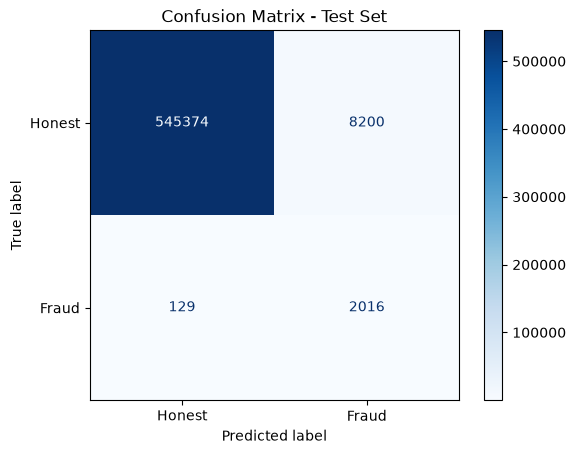

In [9]:
cm = confusion_matrix(testy, predy)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Honest", "Fraud"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Test Set")
plt.show()

In [10]:
new_row = pd.DataFrame({
    'Unnamed: 0': [555719],
    'trans_date_trans_time': ['2020-12-31 23:04:12'],
    'cc_num': [6538441737335434],
    'merchant': ['fraud_Kilback-Rutherford'],
    'category': ['shopping_net'],
    'amt': [942.17],
    'first': ['Gina'],
    'last': ['Grimes'],
    'gender': ['F'],
    'street': ['444 Robert Mews'],
    'city': ['Clarks Mills'],
    'state': ['PA'],
    'zip': [16114],
    'lat': [41.3851],
    'long': [-80.1752],
    'city_pop': [606],
    'job': ['Energy manager'],
    'dob': ['1997-09-22'],
    'trans_num': ['a1b2c3d4e5f6a7b8c9d0e1f2a3b4c5d6'],
    'unix_time': [1388531100],
    'merch_lat': [41.9021],
    'merch_long': [-80.4433]
})

combined_with_new = pd.concat([combined_raw, new_row], ignore_index=True)
combined_with_new = FeatureTransformation(combined_with_new)   # cc_num is real for every row now
new_row_transformed = combined_with_new.iloc[[-1]]

prediction = pipe.predict(new_row_transformed)
result = "Fraud Transaction" if prediction[0] == 1 else "Honest Transaction"
print("The Transaction is a", result)

The Transaction is a Fraud Transaction
